# EDA temporal: quando o ônibus atrasa?

Linha **415 (Usina ↔ Leblon)**, de 25/01 a 21/03/2019. Cada linha da tabela é um
**trecho** entre duas paradas consecutivas de uma viagem, com o tempo que o ônibus
levou (`travel_time_s`), interpolado a partir do GPS por `src/rio_segments.py`.

Perguntas:
1. Em que horário e dia da semana o ônibus é mais lento?
2. Dia útil vs. fim de semana.
3. O que aconteceu no Carnaval (02 a 06/03)?
4. O dia 10/03, quase sem dados.
5. Qualidade do GPS e outliers: justificativa da preparação (`src/prep.py`).

**Medida de lentidão.** Trechos têm tamanhos diferentes (de 100 m a 3 km), então
comparar o tempo bruto mistura "trecho longo" com "trânsito lento". Usamos o
**índice de lentidão** = tempo do trecho ÷ mediana daquele trecho em todo o
período. Índice 1,2 significa 20% mais lento que o normal *para aquele trecho*.

In [1]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # No Colab: clonar o repositório e colocar o parquet em /content/onibus-ia/
    # (ou montar o Drive e ajustar DATA_PATH).
    ROOT = Path("/content/onibus-ia")
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_PATH = ROOT / "segments_415_v0.parquet"
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import prep

pd.set_option("display.precision", 2)
plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titlesize": 12, "axes.titleweight": "bold",
})
COLOR = {"útil": "#2a78d6", "sábado": "#1baf7a", "domingo": "#6250d6",
         "carnaval": "#eb6834"}
MUTED = "#8a8984"
DAY_ORDER = ["útil", "sábado", "domingo", "carnaval"]
from matplotlib.patches import Patch
DAY_HANDLES = [Patch(color=COLOR[d], label=d) for d in DAY_ORDER]

## 1. Visão geral

In [2]:
raw = pd.read_parquet(DATA_PATH)
seg = prep.add_calendar(raw)
seg["service_date"] = pd.to_datetime(seg["service_date"])
seg["speed_kmh"] = seg["distance_m"] / seg["travel_time_s"] * 3.6
segment_median = seg.groupby(prep.SEGMENT_KEY)["travel_time_s"].transform("median")
seg["slowness"] = seg["travel_time_s"] / segment_median

print(f"{len(seg):,} trechos | {seg['trip_id'].nunique():,} viagens | "
      f"{seg['vehicle'].nunique()} veículos | "
      f"{seg['service_date'].min():%d/%m} a {seg['service_date'].max():%d/%m}")
seg[["distance_m", "travel_time_s", "speed_kmh", "max_gap_s", "slowness"]].describe(
    percentiles=[0.01, 0.5, 0.99]).T

370,784 trechos | 29,670 viagens | 122 veículos | 25/01 a 21/03


,count,mean,std,min,1%,50%,99%,max
distance_m,370784.0,338.26,164.86,109.81,137.06,301.57,772.52,3784.52
travel_time_s,370784.0,74.31,55.11,6.17,15.68,60.29,273.99,1913.91
speed_kmh,370784.0,20.13,9.59,0.33,4.65,18.39,51.79,79.91
max_gap_s,370784.0,160.67,70.55,17.00,52.00,153.00,299.00,300.00
slowness,370784.0,1.10,0.57,0.13,0.38,1.00,3.12,36.82


### Volume de trechos por dia

O volume já conta parte da história: fins de semana têm menos viagens, o Carnaval
derruba a operação e o dia 10/03 praticamente some.

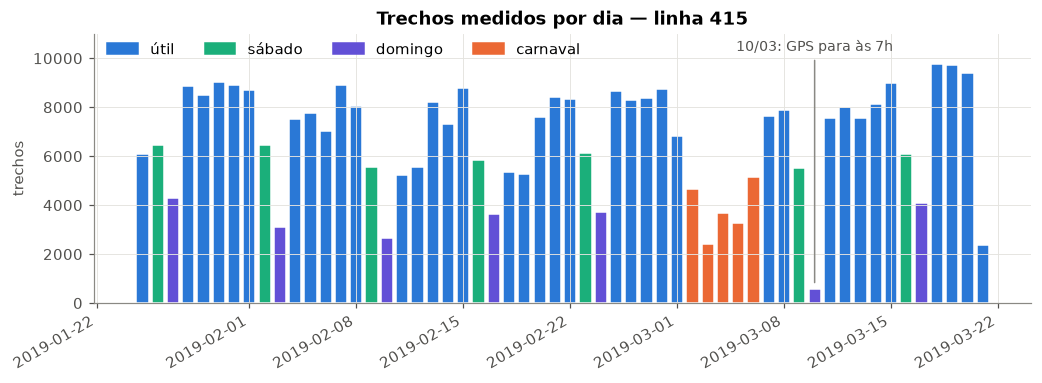

In [3]:
daily = seg.groupby("service_date").agg(n=("trip_id", "size"),
                                        day_type=("day_type", "first"))
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(daily.index, daily["n"], width=0.8,
       color=[COLOR[d] for d in daily["day_type"]], edgecolor="white", linewidth=1)
ax.annotate("10/03: GPS para às 7h", xy=(pd.Timestamp("2019-03-10"), daily.loc["2019-03-10", "n"] + 150),
            xytext=(pd.Timestamp("2019-03-10"), 10_300), fontsize=9, color="#52514e", ha="center",
            arrowprops=dict(arrowstyle="-", color=MUTED))
ax.set_title("Trechos medidos por dia — linha 415")
ax.set_ylabel("trechos")
ax.legend(handles=DAY_HANDLES, ncols=4, frameon=False, loc="upper left", bbox_to_anchor=(0, 1.02))
ax.set_ylim(0, 11_000)
fig.autofmt_xdate()
plt.show()

## 2. Hora do dia e dia da semana

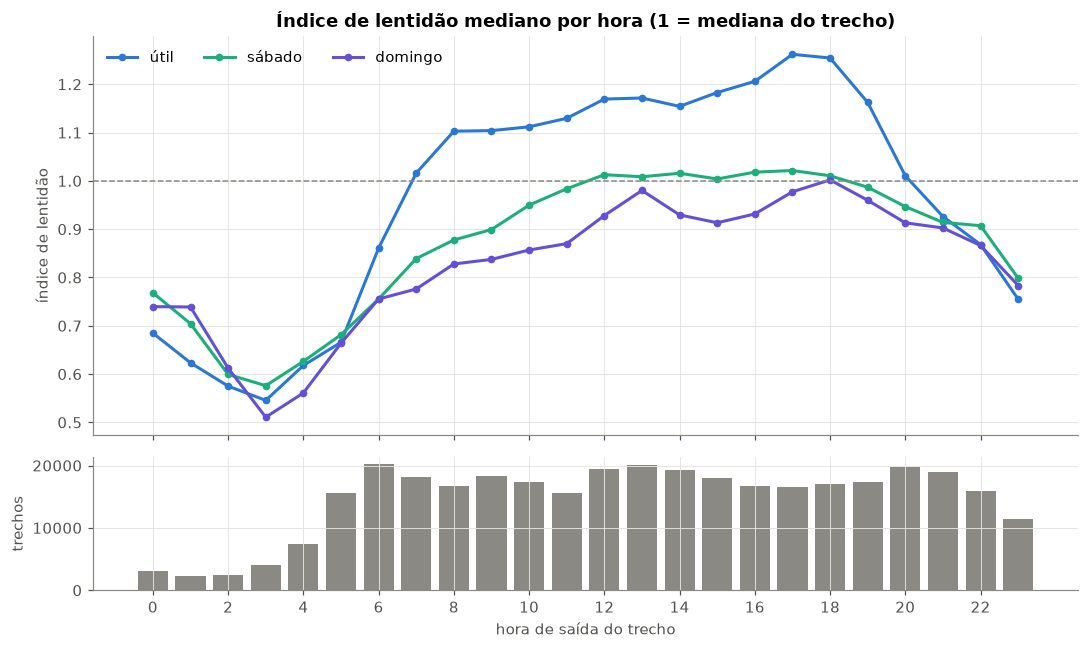

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
day_type,,,,,,,,,,,,,,,,,,,,,
útil,0.68,0.62,0.58,0.55,0.62,0.67,0.86,1.02,1.10,1.10,...,1.15,1.18,1.21,1.26,1.25,1.16,1.01,0.93,0.87,0.76
sábado,0.77,0.70,0.60,0.58,0.63,0.68,0.76,0.84,0.88,0.90,...,1.02,1.00,1.02,1.02,1.01,0.99,0.95,0.91,0.91,0.80
domingo,0.74,0.74,0.61,0.51,0.56,0.66,0.76,0.78,0.83,0.84,...,0.93,0.91,0.93,0.98,1.00,0.96,0.91,0.90,0.87,0.78


In [4]:
regular = seg[~seg["is_carnival"]]
by_hour = (regular.groupby(["day_type", "hour"])["slowness"].median()
           .unstack(0)[["útil", "sábado", "domingo"]])
count_hour = regular.groupby("hour").size()

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True,
                              gridspec_kw={"height_ratios": [3, 1]})
for d in by_hour.columns:
    ax.plot(by_hour.index, by_hour[d], color=COLOR[d], lw=2, marker="o", ms=4, label=d)
ax.axhline(1, color=MUTED, lw=1, ls="--")
ax.set_title("Índice de lentidão mediano por hora (1 = mediana do trecho)")
ax.set_ylabel("índice de lentidão")
ax.legend(frameon=False, ncols=3, loc="upper left")
ax2.bar(count_hour.index, count_hour.values, color=MUTED, width=0.8)
ax2.set_ylabel("trechos")
ax2.set_xlabel("hora de saída do trecho")
ax2.set_xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()
by_hour.round(2).T

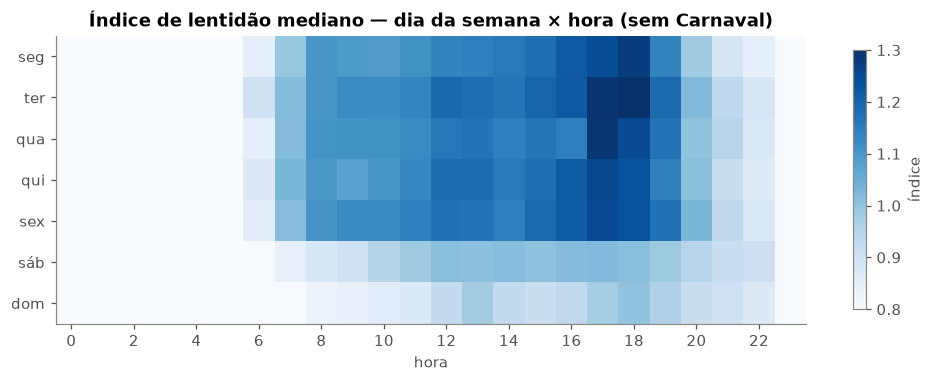

In [5]:
heat = (regular.groupby(["weekday", "hour"])["slowness"].median().unstack("hour"))
fig, ax = plt.subplots(figsize=(11, 3.4))
im = ax.imshow(heat.values, aspect="auto", cmap="Blues", vmin=0.8, vmax=1.3)
ax.set_yticks(range(7), prep.WEEKDAY_NAMES)
ax.set_xticks(range(0, 24, 2), range(0, 24, 2))
ax.grid(False)
ax.set_xlabel("hora")
ax.set_title("Índice de lentidão mediano — dia da semana × hora (sem Carnaval)")
fig.colorbar(im, ax=ax, label="índice", shrink=0.9)
plt.show()

### Dia útil vs. fim de semana

In [6]:
summary = (seg.groupby("day_type")
           .agg(trechos=("slowness", "size"),
                dias=("service_date", "nunique"),
                tempo_mediano_s=("travel_time_s", "median"),
                velocidade_mediana_kmh=("speed_kmh", "median"),
                lentidao_mediana=("slowness", "median"),
                lentidao_p90=("slowness", lambda x: x.quantile(0.9)))
           .reindex(DAY_ORDER))
summary["trechos_por_dia"] = summary["trechos"] / summary["dias"]
summary

,trechos,dias,tempo_mediano_s,velocidade_mediana_kmh,lentidao_mediana,lentidao_p90,trechos_por_dia
day_type,,,,,,,
útil,287508,37,62.37,17.76,1.04,1.71,7770.49
sábado,42023,7,55.75,20.09,0.91,1.42,6003.29
domingo,22059,7,53.08,21.00,0.87,1.32,3151.29
carnaval,19194,5,51.71,20.84,0.87,1.41,3838.80


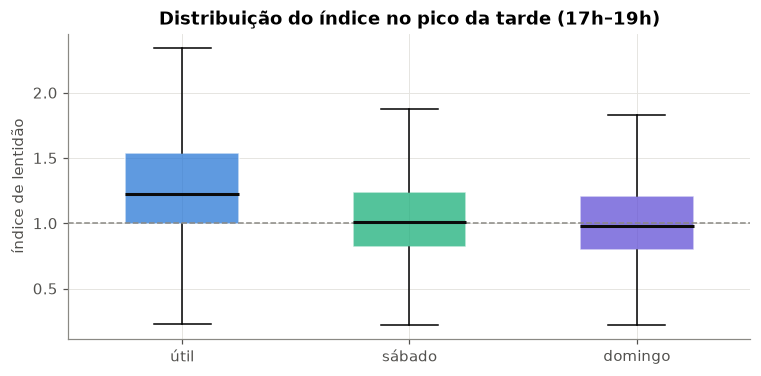

In [7]:
peak = regular[regular["hour"].between(17, 19)]
fig, ax = plt.subplots(figsize=(8, 3.6))
data = [peak.loc[peak["day_type"] == d, "slowness"].clip(upper=3) for d in DAY_ORDER[:3]]
bp = ax.boxplot(data, tick_labels=DAY_ORDER[:3], showfliers=False, patch_artist=True,
                medianprops=dict(color="#0b0b0b", lw=2), widths=0.5)
for patch, d in zip(bp["boxes"], DAY_ORDER[:3]):
    patch.set_facecolor(COLOR[d]); patch.set_alpha(0.75); patch.set_edgecolor("white")
ax.axhline(1, color=MUTED, lw=1, ls="--")
ax.set_ylabel("índice de lentidão")
ax.set_title("Distribuição do índice no pico da tarde (17h–19h)")
plt.show()

## 3. Carnaval (sáb 02/03 a qua 06/03)

Comparamos cada dia de Carnaval com a mediana dos **mesmos dias da semana** fora
do Carnaval (ex.: segunda 04/03 vs. as outras segundas).

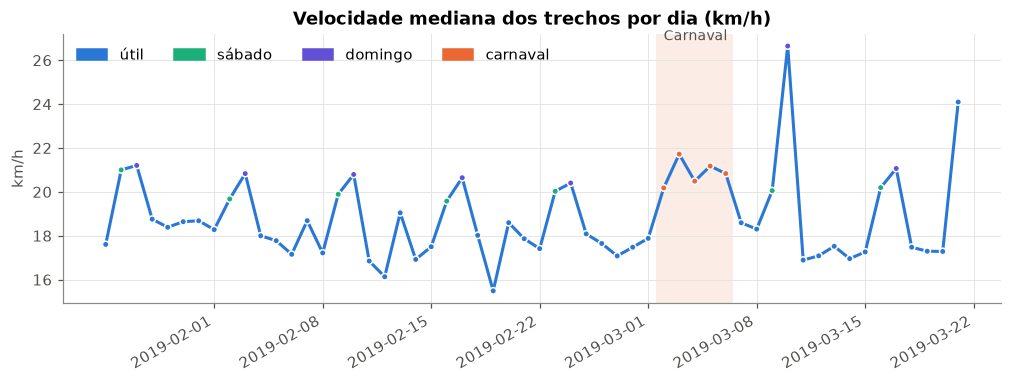

In [8]:
daily_slow = seg.groupby("service_date").agg(slowness=("slowness", "median"),
                                             speed=("speed_kmh", "median"),
                                             day_type=("day_type", "first"),
                                             weekday=("weekday", "first"))
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.axvspan(pd.Timestamp("2019-03-01 12:00"), pd.Timestamp("2019-03-06 12:00"),
           color=COLOR["carnaval"], alpha=0.12, lw=0)
ax.text(pd.Timestamp("2019-03-02"), daily_slow["speed"].max() * 1.01, "Carnaval",
        color="#52514e", fontsize=9)
ax.plot(daily_slow.index, daily_slow["speed"], color=COLOR["útil"], lw=2)
ax.scatter(daily_slow.index, daily_slow["speed"], s=18, zorder=3,
           c=[COLOR[d] for d in daily_slow["day_type"]], edgecolor="white", linewidth=1)
ax.legend(handles=DAY_HANDLES, ncols=4, frameon=False, loc="upper left")
ax.set_title("Velocidade mediana dos trechos por dia (km/h)")
ax.set_ylabel("km/h")
fig.autofmt_xdate()
plt.show()

In [9]:
normal_by_weekday = (daily_slow[daily_slow["day_type"] != "carnaval"]
                     .groupby("weekday")[["slowness", "speed"]].median())
carnival = daily_slow[daily_slow["day_type"] == "carnaval"].copy()
carnival["dia"] = [prep.WEEKDAY_NAMES[w] for w in carnival["weekday"]]
carnival["velocidade_normal"] = normal_by_weekday.loc[carnival["weekday"], "speed"].to_numpy()
carnival["trechos"] = daily.loc[carnival.index, "n"]
carnival["trechos_normal"] = (daily.assign(weekday=daily.index.day_of_week)
                              .query("day_type != 'carnaval'")
                              .groupby("weekday")["n"].median()
                              .loc[carnival["weekday"]].to_numpy())
carnival[["dia", "speed", "velocidade_normal", "trechos", "trechos_normal"]].rename(
    columns={"speed": "velocidade"})

,dia,velocidade,velocidade_normal,trechos,trechos_normal
service_date,,,,,
2019-03-02,sáb,20.18,20.03,4673,6076.0
2019-03-03,dom,21.72,20.83,2433,3637.0
2019-03-04,seg,20.49,18.00,3679,7544.0
2019-03-05,ter,21.18,17.29,3271,8007.0
2019-03-06,qua,20.83,17.52,5138,8217.0


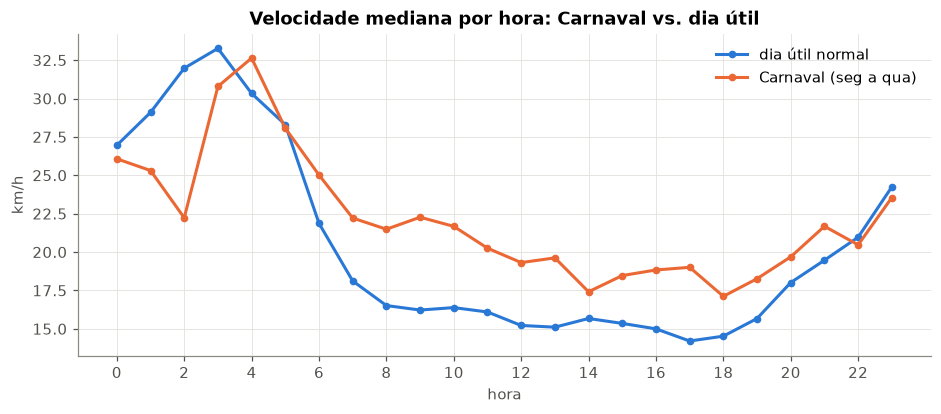

In [10]:
weekday_carnival = seg[seg["is_carnival"] & (seg["weekday"] < 5)]
weekday_normal = regular[regular["weekday"] < 5]
profile = pd.DataFrame({
    "carnaval (seg–qua)": weekday_carnival.groupby("hour")["speed_kmh"].median(),
    "útil normal": weekday_normal.groupby("hour")["speed_kmh"].median(),
})
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(profile.index, profile["útil normal"], color=COLOR["útil"], lw=2, marker="o", ms=4,
        label="dia útil normal")
ax.plot(profile.index, profile["carnaval (seg–qua)"], color=COLOR["carnaval"], lw=2,
        marker="o", ms=4, label="Carnaval (seg a qua)")
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("hora"); ax.set_ylabel("km/h")
ax.set_title("Velocidade mediana por hora: Carnaval vs. dia útil")
ax.legend(frameon=False)
plt.show()

## 4. O dia 10/03

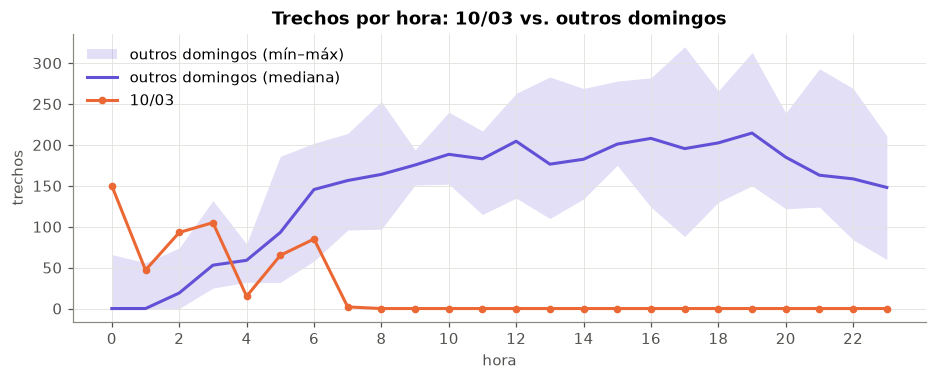

trechos em 10/03: 562 | mediana dos outros domingos: 3679


In [11]:
sundays = seg[(seg["weekday"] == 6) & ~seg["is_carnival"]]
per_hour = (sundays.groupby([sundays["service_date"].dt.date, "hour"]).size()
            .unstack(0).fillna(0))
mar10 = pd.Timestamp("2019-03-10").date()
others = per_hour.drop(columns=mar10)
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.fill_between(others.index, others.min(axis=1), others.max(axis=1),
                color=COLOR["domingo"], alpha=0.18, lw=0, label="outros domingos (mín–máx)")
ax.plot(others.index, others.median(axis=1), color=COLOR["domingo"], lw=2,
        label="outros domingos (mediana)")
ax.plot(per_hour.index, per_hour[mar10], color=COLOR["carnaval"], lw=2, marker="o", ms=4,
        label="10/03")
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("hora"); ax.set_ylabel("trechos")
ax.set_title("Trechos por hora: 10/03 vs. outros domingos")
ax.legend(frameon=False)
plt.show()
print("trechos em 10/03:", int(per_hour[mar10].sum()),
      "| mediana dos outros domingos:", int(others.sum().median()))

## 5. Qualidade do GPS e outliers (justificativa de `src/prep.py`)

`max_gap_s` é o maior intervalo entre os dois pings usados para interpolar o
horário nas paradas do trecho. Quanto maior, mais "chutado" é o tempo.

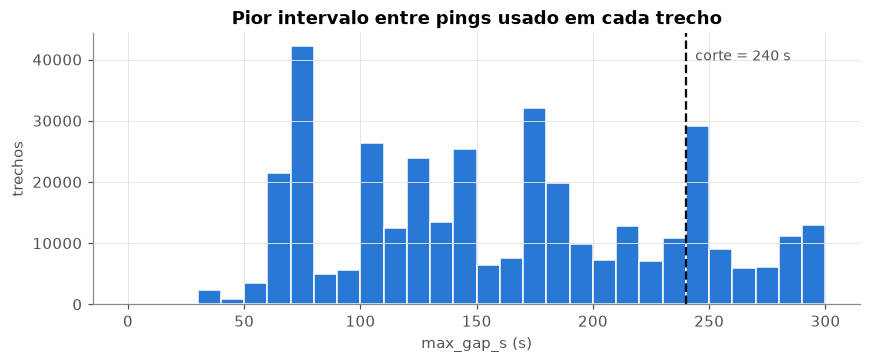

,limite_s,trechos_mantidos_%,lentidao_mediana
0,120,35.15,0.90
1,150,49.65,0.93
2,180,63.54,0.96
3,240,81.28,0.98
4,300,100.00,1.00


In [12]:
thresholds = [120, 150, 180, 240, 300]
kept = pd.DataFrame({
    "limite_s": thresholds,
    "trechos_mantidos_%": [100 * (seg["max_gap_s"] <= t).mean() for t in thresholds],
    "lentidao_mediana": [seg.loc[seg["max_gap_s"] <= t, "slowness"].median() for t in thresholds],
})
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(seg["max_gap_s"], bins=np.arange(0, 310, 10), color=COLOR["útil"],
        edgecolor="white", linewidth=1)
ax.axvline(prep.MAX_GAP_S, color="#0b0b0b", lw=1.5, ls="--")
ax.text(prep.MAX_GAP_S + 4, ax.get_ylim()[1] * 0.9, f"corte = {prep.MAX_GAP_S:.0f} s",
        fontsize=9, color="#52514e")
ax.set_xlabel("max_gap_s (s)"); ax.set_ylabel("trechos")
ax.set_title("Pior intervalo entre pings usado em cada trecho")
plt.show()
kept

In [13]:
error_by_gap = (seg.assign(gap_bin=pd.cut(seg["max_gap_s"], [0, 60, 120, 180, 240, 300]))
                .groupby("gap_bin", observed=True)["slowness"]
                .agg(trechos="size", mediana="median",
                     dispersao_iqr=lambda x: x.quantile(0.75) - x.quantile(0.25)))
error_by_gap

,trechos,mediana,dispersao_iqr
gap_bin,,,
"(0, 60]",17325,0.78,0.45
"(60, 120]",113005,0.92,0.49
"(120, 180]",105264,1.02,0.49
"(180, 240]",65767,1.07,0.50
"(240, 300]",69423,1.08,0.51


**Outliers.** Os limites p1–p99 são calculados **por trecho** (linha, sentido,
parada) e **somente no treino**, e depois aplicados a validação e teste — assim
nenhuma informação do futuro vaza para a preparação. Trechos com menos de 30
observações no treino são descartados (não dá para estimar limites nem treinar
para eles; na 415 isso remove o miolo do Centro, onde o trajeto de 2020 não bate
com o GPS de 2019).

In [14]:
splits = prep.prepare(raw)
after_gap = prep.filter_quality(prep.add_calendar(raw))
tr, va, te = prep.temporal_split(after_gap)
funnel = pd.DataFrame({
    "antes": [len(tr), len(va), len(te)],
    "depois": [len(splits.train), len(splits.val), len(splits.test)],
    "dias": [splits.train["service_date"].nunique(), splits.val["service_date"].nunique(),
             splits.test["service_date"].nunique()],
}, index=["treino (25/01–03/03)", "validação (04–07/03)", "teste (11–20/03)"])
funnel["removidos_%"] = 100 * (1 - funnel["depois"] / funnel["antes"])
print(f"Bruto: {len(raw):,} | após corte de gap: {len(after_gap):,} "
      f"({100 * len(after_gap) / len(raw):.1f}%)")
funnel

Bruto: 370,784 | após corte de gap: 301,361 (81.3%)


,antes,depois,dias,removidos_%
treino (25/01–03/03),207864,203548,38,2.08
validação (04–07/03),16102,15813,4,1.79
teste (11–20/03),64056,62779,10,1.99


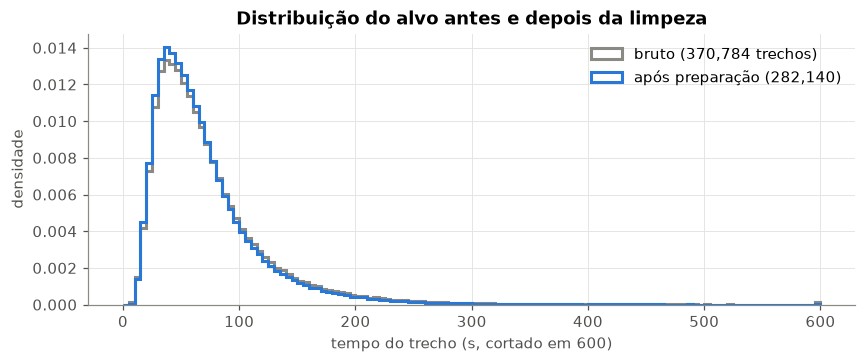

In [15]:
clean_all = pd.concat([splits.train, splits.val, splits.test])
bins = np.arange(0, 605, 5)
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(seg["travel_time_s"].clip(upper=600), bins=bins, density=True, histtype="step",
        color=MUTED, lw=2, label=f"bruto ({len(seg):,} trechos)")
ax.hist(clean_all["travel_time_s"].clip(upper=600), bins=bins, density=True, histtype="step",
        color=COLOR["útil"], lw=2, label=f"após preparação ({len(clean_all):,})")
ax.set_xlabel("tempo do trecho (s, cortado em 600)"); ax.set_ylabel("densidade")
ax.set_title("Distribuição do alvo antes e depois da limpeza")
ax.legend(frameon=False)
plt.show()

## 6. Conclusões

**Hora do dia.** Em dia útil, a lentidão sobe a partir das 6h, fica num patamar de
10–17% acima do normal entre 8h e 16h e atinge o **pico às 17–18h (índice ≈ 1,26)**.
A velocidade mediana cai de ~33 km/h de madrugada para ~14 km/h às 17h. As células
mais lentas do mapa de calor são **terça e quarta, 17–18h**.

**Dia útil vs. fim de semana.** Sábado fica perto do normal durante o dia (≈ 1,0) e
domingo abaixo (≈ 0,9). No pico da tarde, a mediana do dia útil é ~22% maior que
a do fim de semana. O *formato* da curva muda com o tipo de dia, não só o nível.

**Carnaval.** Seg–qua de Carnaval foram **15–22% mais rápidos** que os mesmos dias
normais (≈ 21 km/h vs. 17–18 km/h), com cerca de **metade dos trechos** (frota
reduzida). Na prática, o Carnaval se comporta como um domingo. O sábado e o
domingo de Carnaval ficaram parecidos com fins de semana comuns.

**10/03 e 21/03.** Em 10/03 o GPS para por volta das 7h (562 trechos, contra ~3.700
num domingo típico). Em 21/03 os dados vão só até 8h30. Os dois dias têm só
madrugada, por isso aparecem como "dias rápidos" no gráfico de velocidade. É um
artefato de coleta, e os dois ficam fora do split.

**Qualidade do GPS.** Trechos com pings mais espaçados são, em mediana, **mais
lentos** (índice 0,78 com gap ≤ 60 s vs. 1,08 com gap > 240 s). Então o corte por
`max_gap_s` não é neutro: filtrar demais **enviesa a base para trechos rápidos**.
Com corte em 180 s (o valor do plano), sobram 64% dos trechos e a mediana cai para
0,96; com **240 s, sobram 81% e a mediana fica em 0,98**. Adotamos 240 s.

**Outliers e split.** Os limites p1–p99 por trecho, calculados só no treino, removem
~2% de cada split. O split final tem 38 dias de treino, 4 de validação (Carnaval)
e 10 de teste.

**Implicações para os modelos.**
- A relação com a hora tem dois "degraus" e um pico, ou seja, não é linear. Para
  o **Ridge**, seno/cosseno da hora não bastam: usar a hora em one-hot e a
  interação hora × tipo de dia. Árvores (**LightGBM**) capturam isso sozinhas.
- O tipo de dia (útil / sábado / domingo / Carnaval) é uma variável essencial.
- A validação inclui o Carnaval, que é atípico. Por isso os ajustes feitos na
  validação devem ser conferidos com cuidado, e o teste (11–20/03) é o que
  representa a operação normal.